In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import numpy.typing as npt
import random 
import matplotlib.pyplot as plt
import pandas as pd
import time
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from math import sqrt
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline


In [3]:
df = pd.read_csv('gazebo_dataset_synced.csv')

In [4]:
df

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,76.109,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...,...,...,...,...
95865,1354.681,-0.154206,-0.471443,0.801403,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,1354.681,-0.154157,-0.471496,0.801452,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,1354.681,-0.154109,-0.471548,0.801501,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,1354.681,-0.154060,-0.471601,0.801549,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [5]:
df.describe()

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
count,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000
mean,1510.495158,0.049861,0.022569,0.762274,-0.125948,0.046854,-0.352591,0.800791,-0.258203,-1.375961,-0.190765
std,2219.154855,0.333866,0.352429,0.361617,1.646092,0.954804,2.025295,3.572670,1.530393,7.763283,1.752245
min,76.109000,-0.794150,-0.840471,-0.716202,-2.773854,-2.028950,-8.088039,-2.104892,-2.940508,-43.638002,-16.426336
25%,201.154000,-0.154784,-0.232761,0.478756,-1.540355,-0.570780,-1.313833,-0.620000,-1.628157,-0.828176,-1.351246
50%,315.650000,0.023001,-0.000005,0.789397,0.000013,0.000067,-0.000066,0.049822,-0.000070,-0.000016,-0.000057
75%,1265.010000,0.277337,0.290886,1.075479,1.090419,0.788004,0.909329,1.135364,0.714148,0.831085,0.816528
max,6658.649000,1.000957,0.831571,1.220999,2.867152,1.904753,2.846485,19.466906,2.922250,2.400718,2.957545


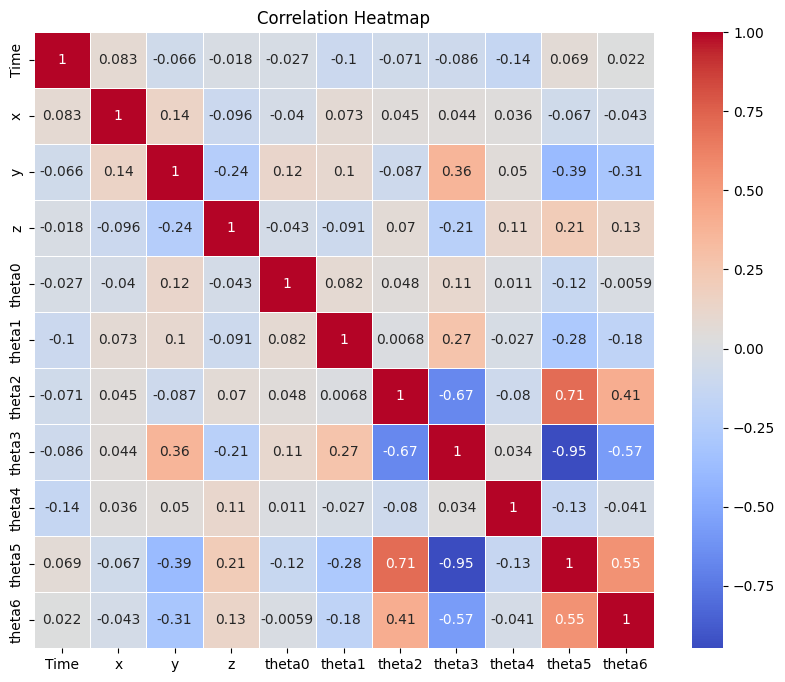

In [6]:
#Plotting correlation heatmap
correlation_matrix =df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5) 
plt.title("Correlation Heatmap")
plt.show()

In [7]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
95865,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [8]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
95865,-0.154206,-0.471443,0.801403
95866,-0.154157,-0.471496,0.801452
95867,-0.154109,-0.471548,0.801501
95868,-0.154060,-0.471601,0.801549


In [9]:
X.shape

(95870, 3)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.fit_transform(X_test)

In [11]:
X_train = np.array(X_train)
X_test = np.array(X_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

## Decision Tree Regressor

In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Create the Decision Tree Regressor model
dt_regressor = DecisionTreeRegressor(max_depth=20, 
                                     min_samples_leaf=15, 
                                     random_state=42)

# Train the model using the training dataset
dt_regressor.fit(X_train, y_train)

# Predict joint angles using the trained Decision Tree model on the test set
predictions = dt_regressor.predict(X_test)

# Calculate the mean squared error
mse = mean_squared_error(y_test, predictions)
print(f"Mean Squared Error: {mse}")

Mean Squared Error: 0.13159118231106254


Mean Absolute Error: 0.08813846661179948
Mean Squared Error: 0.13159118231106254
Root Mean Squared Error: 0.34926347838923133
R-squared: 0.9895830661670262
Explained Variance Score: 0.9687404518975481


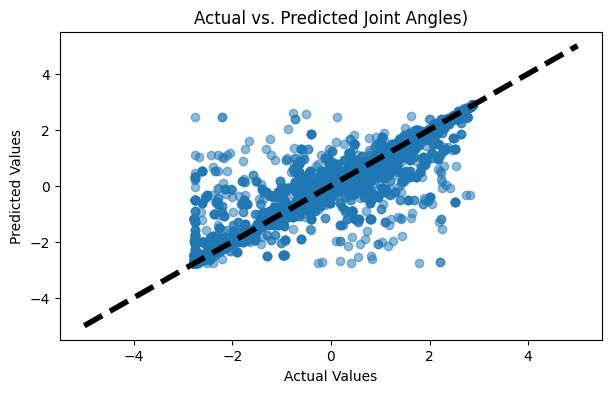

In [20]:
# Evaluate the model performance

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions, squared=False)  # Set squared=False for RMSE
r2 = r2_score(y_test, predictions, multioutput='variance_weighted')  # For multi-output
explained_variance = explained_variance_score(y_test, predictions)

print(f"Mean Absolute Error: {mae}")
print(f"Mean Squared Error: {mse}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")
print(f"Explained Variance Score: {explained_variance}")

# Plotting actual vs predicted values for the first dimension as an example
plt.figure(figsize=(7, 4))
plt.scatter(y_test[:, 0], predictions[:, 0], alpha=0.5)
plt.title('Actual vs. Predicted Joint Angles)')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.plot([-5,5], [-5,5], 'k--', lw=4)
plt.show()

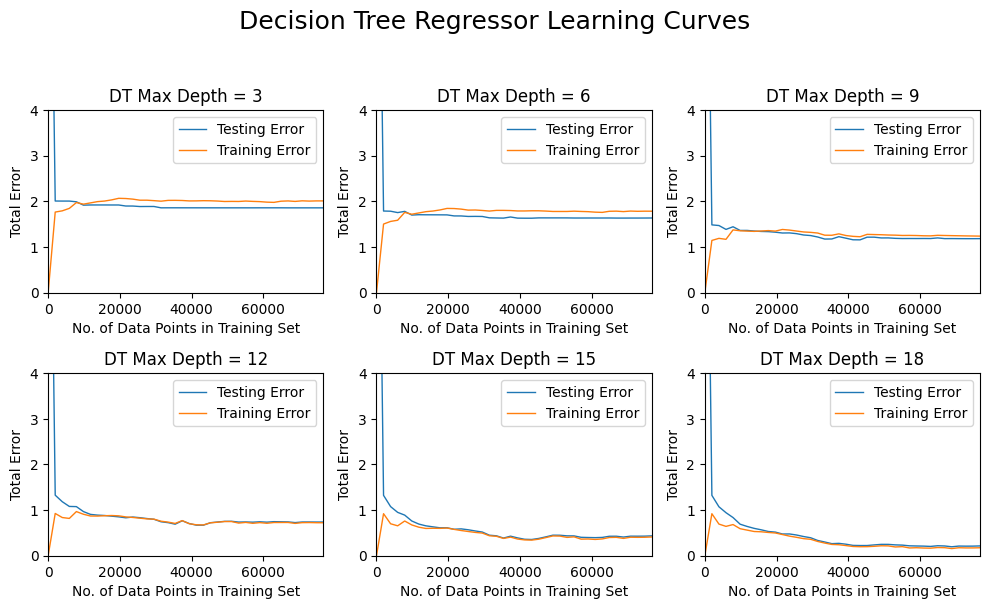

In [21]:
def learning_curves(X_train, y_train, X_test, y_test):
    # Both X_train and y_train have 354 rows, and X_test and y_test have 152 rows
    fig = plt.figure(figsize=(10,8))
    # Generate 40 evenly spaced numbers (rounded to nearest integer) over a specified interval 1 to 354
    datapoints = np.rint(np.linspace(1, len(X_train), 40)).astype(int)
    #initialise array of shape (40,)
    train_err = np.zeros(len(datapoints))
    test_err = np.zeros(len(datapoints))

    # Create 6 different models based on max_depth
    for k, depth in enumerate(range(1,7)):
        for i, s in enumerate(datapoints):
            reg = DecisionTreeRegressor(max_depth = depth*3,
                                        min_samples_leaf=15, 
                                        random_state=42) #increasing depth
            # Iteratively increase training set size
            reg.fit(X_train[:s], y_train[:s])
            # MSE for training and test sets of increasing size
            train_err[i] = mean_squared_error(y_train[:s], reg.predict(X_train[:s]))
            test_err[i] = mean_squared_error(y_test, reg.predict(X_test))

        # Subplot learning curves
        sub = fig.add_subplot(3, 3, k+1)
        sub.plot(datapoints, test_err, lw = 1, label = 'Testing Error')
        sub.plot(datapoints, train_err, lw = 1, label = 'Training Error')
        sub.legend()
        sub.set_title('DT Max Depth = %s'%(depth*3))
        sub.set_xlabel('No. of Data Points in Training Set')
        sub.set_ylabel('Total Error')
        sub.set_xlim([0, len(X_train)])
        sub.set_ylim([0, 4])

    fig.suptitle('Decision Tree Regressor Learning Curves', fontsize=18, y=1.03)
    fig.tight_layout()
    
learning_curves(X_train, y_train, X_test, y_test)

In [15]:
# Print the predicted joint angles from the Decision Tree model
print("Test Joint Angles (y_test):")
print(np.array(y_test[5,:]))

# If you want to predict joint angles for specific end-effector positions, you can do so as follows:
test_end_effector_positions = np.array([X_test[5,:]])#, [0.0, 0.0, 0.0]])  # Replace with actual positions
predicted_joint_angles_specific = dt_regressor.predict(test_end_effector_positions)
print("\nPredicted Joint Angles for Specific Positions (Decision Tree):")
#print("{:.2f}".format(predicted_joint_angles_specific))## Decision Tree Regressor
print(np.round(predicted_joint_angles_specific, 3))

Test Joint Angles (y_test):
[-2.75914997 -0.2760216  -2.71863528 -0.48817733 -2.17682328  0.8311709
 -2.19984127]

Predicted Joint Angles for Specific Positions (Decision Tree):
[[-2.759 -0.276 -2.719 -0.488 -2.177  0.831 -2.2  ]]


In [16]:
#y_pred = pd.DataFrame(y_scaler.inverse_transform(y_pred))
#y_test = pd.DataFrame(y_scaler.inverse_transform(y_test))

result_mse = []
result_mae = []

for i in range(7):

    mse = mean_squared_error(y_test[:,i], predictions[:,i])
    rmse = sqrt(mse) 
    mae = mean_absolute_error(y_test[:,i], predictions[:,i])
    result_mse.append(mse)
    result_mae.append(mae)

print("RMSE:\n", np.round(result_mse,4))
print("\nMAE:\n", np.round(result_mae,4))

RMSE:
 [0.1318 0.0252 0.128  0.0992 0.1321 0.2699 0.1349]

MAE:
 [0.1056 0.0444 0.0981 0.067  0.107  0.0842 0.1107]


-
-
-
-